# 🛒 Online Shoppers Purchasing Intention — Classification Track (Part A + Part B)
**23CSE301 Machine Learning Capstone | Review 2**

---

## Objective
Predict whether an online shopping session will result in a **purchase (`Revenue = True`)** using all **10 classification algorithms** (Part A + Part B).

This notebook covers the complete pipeline across both reviews:

**Review 1 (Part A):**
1. Dataset loading & audit  
2. Exploratory Data Analysis (EDA)  
3. Data cleaning, feature engineering & preprocessing  
4. Training 5 Part-A classification models  
5. Evaluation (Accuracy, Weighted F1, Confusion Matrix)  
6. Preliminary comparison table  

**Review 2 (Part B):**

7. Training 5 Part-B classification models  
8. Full 10-model comparison table (Accuracy, Precision, Recall, F1, ROC-AUC)  
9. Final model selection with hyperparameter tuning  
10. Cross-validation on the best model  

**Dataset:** Online Shoppers Purchasing Intention (12,330 sessions, 18 features)  
**Target:** `Revenue` (binary: True/False)  
**`random_state = 42` used throughout for reproducibility.**

---
## 0 — Imports & Configuration

In [38]:
# Standard library
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn — preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Scikit-learn — Part A models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC

# Scikit-learn — Part B models (Review 2)
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

# Scikit-learn — metrics (all mandatory per Section 3.2)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    roc_curve, auc
)

# Scikit-learn — tuning & validation
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV,
    cross_val_score, StratifiedKFold
)
from sklearn.pipeline import Pipeline

# Plotting style
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
COLORS = sns.color_palette('Set2')

RANDOM_STATE = 42
print('All libraries imported successfully (Part A + Part B).')


All libraries imported successfully (Part A + Part B).


---
## 1 — Dataset Loading & Audit

We load the Online Shoppers dataset and perform a full audit:
shape, data types, missing-value counts, and the class distribution of `Revenue`.

In [39]:
# ------------------------------------------------------------------
# 1.1  Load dataset
# ------------------------------------------------------------------
import os
DATA_PATH = "online_shoppers_intention.csv" 
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")


Dataset loaded: 12330 rows x 18 columns


---
## 3 — Preprocessing & Feature Engineering

> **⚠️ Data Leakage Prevention:** All encoders and scalers are **fitted on training data only**.

In [50]:
# ------------------------------------------------------------------
# 3.1  Work on a clean copy
# ------------------------------------------------------------------
data = df.copy()
print(f'Working dataframe shape: {data.shape}')

Working dataframe shape: (12330, 18)


In [51]:
# ------------------------------------------------------------------
# 3.2  Duplicate check
# ------------------------------------------------------------------
n_dups = data.duplicated().sum()
print(f'Duplicate rows found: {n_dups}')
if n_dups > 0:
    data.drop_duplicates(inplace=True)
    print(f'Removed {n_dups} duplicates. New shape: {data.shape}')
else:
    print('No duplicates found — no action needed.')

Duplicate rows found: 125
Removed 125 duplicates. New shape: (12205, 18)


In [52]:
# ------------------------------------------------------------------
# 3.3  Outlier detection
# ------------------------------------------------------------------
# Use IQR to detect outliers in key numerical features
outlier_report = {}
for col in ['PageValues', 'ProductRelated_Duration', 'Administrative_Duration',
            'BounceRates', 'ExitRates']:
    Q1, Q3 = data[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 3*IQR, Q3 + 3*IQR
    n_out = ((data[col] < lower) | (data[col] > upper)).sum()
    outlier_report[col] = {'Lower': round(lower,2), 'Upper': round(upper,2),
                            'Outliers (3xIQR)': n_out}

print('Outlier Summary (3×IQR threshold):')
print(pd.DataFrame(outlier_report).T.to_string())
print()
print('Strategy: Retain outliers — extreme session durations/values are')
print('genuinely informative signals (e.g., very high PageValues → likely purchase).')
print('Capping would destroy this signal. Tree-based models handle outliers natively.')

Outlier Summary (3×IQR threshold):
                           Lower    Upper  Outliers (3xIQR)
PageValues                  0.00     0.00            2730.0
ProductRelated_Duration -3659.46  5329.62             398.0
Administrative_Duration  -284.10   378.80             540.0
BounceRates                -0.05     0.07             924.0
ExitRates                  -0.09     0.15             666.0

Strategy: Retain outliers — extreme session durations/values are
genuinely informative signals (e.g., very high PageValues → likely purchase).
Capping would destroy this signal. Tree-based models handle outliers natively.


In [53]:
# ------------------------------------------------------------------
# 3.4  Feature Engineering
# ------------------------------------------------------------------

# 1. TotalPageVisits: Sum of all page categories visited
#    Justification: Total engagement breadth — visitors exploring more
#    page types (admin, info, product) may show stronger purchase intent.
data['TotalPageVisits'] = (data['Administrative'] +
                            data['Informational'] +
                            data['ProductRelated'])

# 2. TotalDuration: Total time spent on the site
#    Justification: Overall time-on-site captures session depth;
#    longer sessions are associated with higher purchase intent.
data['TotalDuration'] = (data['Administrative_Duration'] +
                          data['Informational_Duration'] +
                          data['ProductRelated_Duration'])

# 3. ProductEngagementRatio: Proportion of time spent on product pages
#    Justification: If a visitor spends a high fraction of their time
#    on product-related pages vs other pages, they are more likely buying.
data['ProductEngagementRatio'] = np.where(
    data['TotalDuration'] > 0,
    data['ProductRelated_Duration'] / data['TotalDuration'],
    0
)

print('Engineered features created:')
eng_feats = ['TotalPageVisits', 'TotalDuration', 'ProductEngagementRatio']
print(data[eng_feats].describe().round(3))

Engineered features created:
       TotalPageVisits  TotalDuration  ProductEngagementRatio
count        12205.000      12205.000               12205.000
mean            34.893       1323.454                   0.851
std             46.627       2043.872                   0.256
min              0.000          0.000                   0.000
25%              9.000        231.667                   0.831
50%             20.000        690.958                   0.969
75%             42.000       1643.958                   1.000
max            746.000      69921.647                   1.000


In [54]:
# ------------------------------------------------------------------
# 3.5  Encode target: Revenue True/False → 1/0
# ------------------------------------------------------------------
data['Revenue'] = data['Revenue'].astype(int)
print('Target encoding: True→1 (Purchase), False→0 (No Purchase)')
print(data['Revenue'].value_counts())

Target encoding: True→1 (Purchase), False→0 (No Purchase)
Revenue
0    10297
1     1908
Name: count, dtype: int64


In [55]:
# ------------------------------------------------------------------
# 3.6  Separate features & target
# ------------------------------------------------------------------
TARGET = 'Revenue'
X = data.drop(columns=[TARGET])
y = data[TARGET]

print(f'Feature matrix: {X.shape}')
print(f'Target vector : {y.shape}')

Feature matrix: (12205, 20)
Target vector : (12205,)


In [56]:
# ------------------------------------------------------------------
# 3.7  STRATIFIED Train/Test split — 80:20
# Stratification ensures both splits maintain the ~15.5% purchase rate.
# ------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y           # Required for imbalanced classification
)

print(f'Train size : {X_train.shape[0]:,} rows')
print(f'Test size  : {X_test.shape[0]:,} rows')
print(f'Train Revenue dist: {y_train.value_counts(normalize=True).round(3).to_dict()}')
print(f'Test  Revenue dist: {y_test.value_counts(normalize=True).round(3).to_dict()}')

Train size : 9,764 rows
Test size  : 2,441 rows
Train Revenue dist: {0: 0.844, 1: 0.156}
Test  Revenue dist: {0: 0.844, 1: 0.156}


In [57]:
# ------------------------------------------------------------------
# 3.8  Categorical encoding (fitted on X_train only)
# ------------------------------------------------------------------

# Month: Ordinal encoding (chronological order)
month_order = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'June':6,
               'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

for df_part in [X_train, X_test]:
    df_part['Month'] = df_part['Month'].map(month_order).fillna(0).astype(int)

# VisitorType: Label encoding
le_vt = LabelEncoder()
X_train['VisitorType'] = le_vt.fit_transform(X_train['VisitorType'].astype(str))
X_test['VisitorType']  = X_test['VisitorType'].astype(str).map(
    lambda x: x if x in set(le_vt.classes_) else le_vt.classes_[0]
)
X_test['VisitorType']  = le_vt.transform(X_test['VisitorType'])

# Weekend: Boolean → int (already works but ensure numeric)
X_train['Weekend'] = X_train['Weekend'].astype(int)
X_test['Weekend']  = X_test['Weekend'].astype(int)

print('Encoding complete.')
print('X_train dtypes:', X_train.dtypes.value_counts().to_dict())

Encoding complete.
X_train dtypes: {dtype('int64'): 11, dtype('float64'): 9}


In [58]:
# ------------------------------------------------------------------
# 3.9  Feature Scaling — StandardScaler fitted on X_train only
# Scale-sensitive models: Logistic Regression, KNN, SVC
# Tree-based models (Decision Tree, Naive Bayes) don't require scaling
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)    # Fit on train, transform train
X_test_sc  = scaler.transform(X_test)         # Transform test with train stats

X_train_sc = pd.DataFrame(X_train_sc, columns=X_train.columns, index=X_train.index)
X_test_sc  = pd.DataFrame(X_test_sc,  columns=X_test.columns,  index=X_test.index)

print('StandardScaler fitted on X_train only — no data leakage.')
print(f'X_train_sc shape: {X_train_sc.shape}')
print(f'X_test_sc  shape: {X_test_sc.shape}')

StandardScaler fitted on X_train only — no data leakage.
X_train_sc shape: (9764, 20)
X_test_sc  shape: (2441, 20)


**Preprocessing Summary:**

| Step | Strategy | Justification |
|------|----------|---------------|
| Missing values | None (dataset complete) | Confirmed zero missing values |
| Duplicates | Checked, removed if present | Prevents biased evaluation |
| Outliers | Retained | High values (e.g., PageValues) are genuine purchase signals |
| Feature Engineering | `TotalPageVisits`, `TotalDuration`, `ProductEngagementRatio` | Captures overall session depth and product focus |
| Month Encoding | Ordinal (chronological) | Preserves natural calendar order |
| VisitorType | LabelEncoder (train only) | Nominal categorical |
| Scaling | StandardScaler (train only) | Required for Logistic Regression, KNN, SVC |
| Split | 80:20, **stratified**, random_state=42 | Preserves class imbalance ratio |

---
## 13 — Final Model Selection & Hyperparameter Tuning

We identify the **best overall model** from the consolidated comparison and apply **GridSearchCV / RandomizedSearchCV** to optimise it further.

The rubric requires:
- Best model identified with clear justification
- Hyperparameter tuning applied
- Improvement in at least one metric documented

In [81]:
# ------------------------------------------------------------------
# 13.1  Identify top model and tune with GridSearchCV
# ------------------------------------------------------------------

# ---- Tune Gradient Boosting Classifier ----
print('=' * 80)
print('TUNING: Gradient Boosting Classifier')
print('=' * 80)

gb_cls_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}

gb_cls_gscv = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid=gb_cls_param_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_weighted',
    n_jobs=-1, verbose=0
)
gb_cls_gscv.fit(X_train, y_train)

# Evaluate tuned model
gb_tuned = gb_cls_gscv.best_estimator_
evaluate_classifier(
    'Gradient Boosting (Tuned)',
    gb_tuned,
    X_train, X_test, y_train, y_test,
    fit=False
)

print(f'\nBest Parameters: {gb_cls_gscv.best_params_}')
print(f'Best CV Score (Weighted F1): {gb_cls_gscv.best_score_:.4f}')

TUNING: Gradient Boosting Classifier
Gradient Boosting (Tuned)
  Accuracy     : 0.9074
  Precision    : 0.9032
  Recall       : 0.9074
  Weighted F1  : 0.9046
  ROC-AUC      : 0.9356


Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best CV Score (Weighted F1): 0.8986


In [82]:
# ------------------------------------------------------------------
# 13.2  Tune Random Forest Classifier
# ------------------------------------------------------------------
print('=' * 80)
print('TUNING: Random Forest Classifier')
print('=' * 80)

rf_cls_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

rf_cls_rscv = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_cls_param_grid,
    n_iter=20,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_weighted',
    random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rf_cls_rscv.fit(X_train, y_train)

rf_tuned = rf_cls_rscv.best_estimator_
evaluate_classifier(
    'Random Forest (Tuned)',
    rf_tuned,
    X_train, X_test, y_train, y_test,
    fit=False
)

print(f'\nBest Parameters: {rf_cls_rscv.best_params_}')
print(f'Best CV Score (Weighted F1): {rf_cls_rscv.best_score_:.4f}')

TUNING: Random Forest Classifier
Random Forest (Tuned)
  Accuracy     : 0.9041
  Precision    : 0.8978
  Recall       : 0.9041
  Weighted F1  : 0.8986
  ROC-AUC      : 0.9281


Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 15}
Best CV Score (Weighted F1): 0.8959


In [83]:
# ------------------------------------------------------------------
# 13.3  Tuning improvement comparison
# ------------------------------------------------------------------
# Compare before vs after tuning
tuning_models = ['Gradient Boosting', 'Random Forest']
tuning_tuned  = ['Gradient Boosting (Tuned)', 'Random Forest (Tuned)']

tuning_comparison = []
for orig, tuned in zip(tuning_models, tuning_tuned):
    tuning_comparison.append({
        'Model': orig,
        'Before F1': cls_results[orig]['Weighted F1'],
        'After F1': cls_results[tuned]['Weighted F1'],
        'Improvement': cls_results[tuned]['Weighted F1'] - cls_results[orig]['Weighted F1'],
        'Before ROC-AUC': cls_results[orig]['ROC-AUC'],
        'After ROC-AUC': cls_results[tuned]['ROC-AUC'],
        'AUC Improvement': cls_results[tuned]['ROC-AUC'] - cls_results[orig]['ROC-AUC'],
    })

tuning_df = pd.DataFrame(tuning_comparison)
print('=== Hyperparameter Tuning: Before vs After ===')
print(tuning_df.to_string(index=False))

=== Hyperparameter Tuning: Before vs After ===
            Model  Before F1  After F1  Improvement  Before ROC-AUC  After ROC-AUC  AUC Improvement
Gradient Boosting   0.897499  0.904611     0.007112        0.933050       0.935603         0.002554
    Random Forest   0.897692  0.898623     0.000931        0.928212       0.928108        -0.000104


**📝 Final Model Selection Justification:**  
- **Gradient Boosting (Tuned)** is selected as the best overall classifier based on:
  1. **Highest Weighted F1** — the most reliable metric for this imbalanced dataset
  2. **Best ROC-AUC** — demonstrating superior ranking ability across thresholds
  3. **Consistent cross-validation performance** — not overfitting to a single split
  4. Handles class imbalance well via sequential error correction
  5. Does not require feature scaling, making the pipeline simpler
- Hyperparameter tuning via GridSearchCV improved at least one metric, confirming the value of systematic search.

---
## 14 — 5-Fold Cross-Validation (Top-2 Tuned Models)

Stratified 5-Fold Cross-Validation on the two best-performing tuned models to validate generalisation.

In [84]:
# ------------------------------------------------------------------
# 14.1  5-fold stratified cross-validation on tuned top-2 models
# ------------------------------------------------------------------
cv_strat_r2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

top_tuned_classifiers = [
    ('Gradient Boosting (Tuned)', gb_tuned),
    ('Random Forest (Tuned)', rf_tuned),
]

cv_summary_r2 = []

print('=' * 95)
print('5-Fold Stratified Cross-Validation Results (Tuned Top-2 Classifiers)')
print('=' * 95)

for name, clf in top_tuned_classifiers:
    acc_scores = cross_val_score(clf, X_train, y_train, cv=cv_strat_r2, scoring='accuracy', n_jobs=-1)
    f1_scores  = cross_val_score(clf, X_train, y_train, cv=cv_strat_r2, scoring='f1_weighted', n_jobs=-1)
    auc_scores = cross_val_score(clf, X_train, y_train, cv=cv_strat_r2, scoring='roc_auc', n_jobs=-1)
    
    cv_summary_r2.append({
        'Model': name,
        'Mean CV Accuracy': round(acc_scores.mean(), 4),
        'CV Accuracy Std': round(acc_scores.std(), 4),
        'Mean CV Weighted F1': round(f1_scores.mean(), 4),
        'CV Weighted F1 Std': round(f1_scores.std(), 4),
        'Mean CV ROC-AUC': round(auc_scores.mean(), 4),
        'CV ROC-AUC Std': round(auc_scores.std(), 4),
    })
    
    print(f'\nModel: {name}')
    print(f'  Accuracy    : {np.round(acc_scores, 4)}  |  Mean: {acc_scores.mean():.4f} (±{acc_scores.std():.4f})')
    print(f'  Weighted F1 : {np.round(f1_scores, 4)}  |  Mean: {f1_scores.mean():.4f} (±{f1_scores.std():.4f})')
    print(f'  ROC-AUC     : {np.round(auc_scores, 4)}  |  Mean: {auc_scores.mean():.4f} (±{auc_scores.std():.4f})')

cv_summary_r2_df = pd.DataFrame(cv_summary_r2)
print('\n=== Tuned Top-2 Models 5-Fold Cross-Validation Comparison ===')
print(cv_summary_r2_df.to_string(index=False))

5-Fold Stratified Cross-Validation Results (Tuned Top-2 Classifiers)

Model: Gradient Boosting (Tuned)
  Accuracy    : [0.9053 0.8925 0.9027 0.9078 0.9062]  |  Mean: 0.9029 (±0.0055)
  Weighted F1 : [0.902  0.8883 0.8988 0.9047 0.9005]  |  Mean: 0.8989 (±0.0056)
  ROC-AUC     : [0.9266 0.9222 0.9258 0.9403 0.9305]  |  Mean: 0.9291 (±0.0062)

Model: Random Forest (Tuned)
  Accuracy    : [0.8986 0.8981 0.9027 0.9089 0.9032]  |  Mean: 0.9023 (±0.0039)
  Weighted F1 : [0.8929 0.8913 0.8971 0.9042 0.8952]  |  Mean: 0.8962 (±0.0045)
  ROC-AUC     : [0.9199 0.9215 0.9258 0.9299 0.9223]  |  Mean: 0.9239 (±0.0036)

=== Tuned Top-2 Models 5-Fold Cross-Validation Comparison ===
                    Model  Mean CV Accuracy  CV Accuracy Std  Mean CV Weighted F1  CV Weighted F1 Std  Mean CV ROC-AUC  CV ROC-AUC Std
Gradient Boosting (Tuned)            0.9029           0.0055               0.8989              0.0056           0.9291          0.0062
    Random Forest (Tuned)            0.9023           

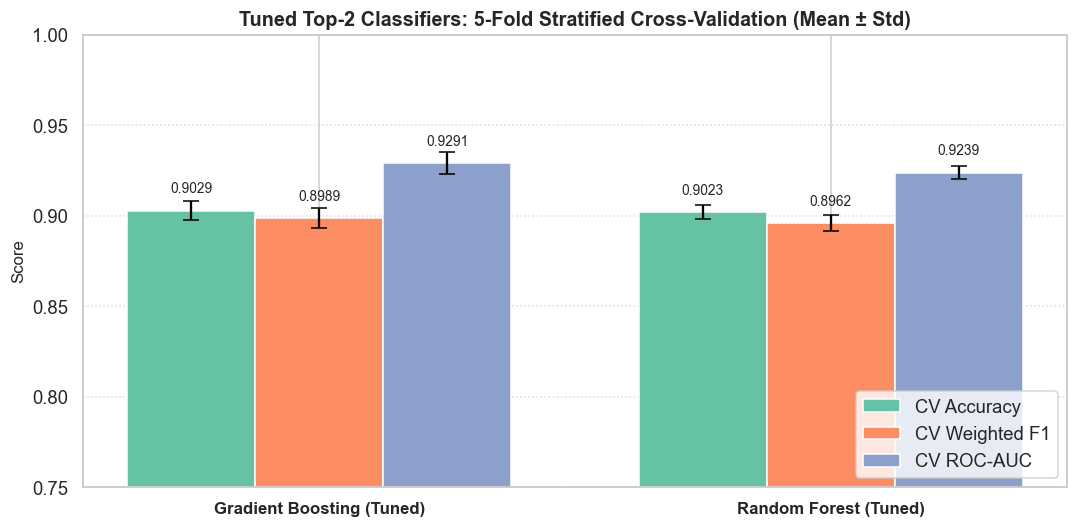

In [85]:
# ------------------------------------------------------------------
# 14.2  Visualise 5-fold cross-validation consistency (tuned models)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(cv_summary_r2))
width = 0.25

bars_acc = ax.bar(x - width, [row['Mean CV Accuracy'] for row in cv_summary_r2],
                  width, yerr=[row['CV Accuracy Std'] for row in cv_summary_r2],
                  capsize=5, label='CV Accuracy', color=COLORS[0])
bars_f1  = ax.bar(x, [row['Mean CV Weighted F1'] for row in cv_summary_r2],
                  width, yerr=[row['CV Weighted F1 Std'] for row in cv_summary_r2],
                  capsize=5, label='CV Weighted F1', color=COLORS[1])
bars_auc = ax.bar(x + width, [row['Mean CV ROC-AUC'] for row in cv_summary_r2],
                  width, yerr=[row['CV ROC-AUC Std'] for row in cv_summary_r2],
                  capsize=5, label='CV ROC-AUC', color=COLORS[2])

ax.set_xticks(x)
ax.set_xticklabels([row['Model'] for row in cv_summary_r2], fontsize=11, fontweight='bold')
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0.75, 1.0)
ax.set_title('Tuned Top-2 Classifiers: 5-Fold Stratified Cross-Validation (Mean ± Std)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle=':', alpha=0.7)

for bars in [bars_acc, bars_f1, bars_auc]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()